In [1]:
!pip install catboost
!pip install optuna

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve

from catboost import CatBoostClassifier
import optuna

from sklearn.metrics import average_precision_score
import lightgbm as lgb

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
df_airlines = pd.read_csv('airlines.csv')
df_airports = pd.read_csv('airports.csv')
df_daily_airport_stats = pd.read_csv('daily_airport_stats.csv')
df_flights = pd.read_parquet('flights.parquet')

print("airlines:")
display(df_airlines.head())
print("\nairposrts")
display(df_airports.head())
print("\ndaily_airport_stats")
display(df_daily_airport_stats.head())
print("\nflights")
display(df_flights.head())

airlines:


,airline_code,airline,flights,on_time_arrival_rate,cancel_rate,first_flight_date,last_flight_date
0,WN,Southwest Airlines,2319717,0.7682,0.0092,2025-01-01,2026-08-31
1,DL,Delta Air Lines,1721263,0.8036,0.0145,2025-01-01,2026-08-31
2,AA,American Airlines,1641071,0.7412,0.0215,2025-01-01,2026-08-31
3,OO,SkyWest Airlines,1416733,0.7866,0.0158,2025-01-01,2026-08-31
4,UA,United Airlines,1354575,0.7842,0.0099,2025-01-01,2026-08-31



airposrts


,iata_code,icao_code,airport_name,city,state,latitude,longitude,elevation_ft,airport_type,departures,arrivals
0,ORD,KORD,Chicago O'Hare International Airport,"Chicago, IL",IL,41.978600,-87.904800,680,large_airport,573580,573532
1,DEN,KDEN,Denver International Airport,"Denver, CO",CO,39.860027,-104.673792,5431,large_airport,531750,531722
2,ATL,KATL,Hartsfield Jackson Atlanta International Airport,"Atlanta, GA",GA,33.636700,-84.428101,1026,large_airport,525113,525091
3,DFW,KDFW,Dallas Fort Worth International Airport,"Dallas/Fort Worth, TX",TX,32.896801,-97.038002,607,large_airport,525000,524995
4,PHX,KPHX,Phoenix Sky Harbor International Airport,"Phoenix, AZ",AZ,33.435302,-112.005905,1135,large_airport,329807,329795



daily_airport_stats


,flight_date,airport,departures_scheduled,cancelled,diverted,dep_delay_mean,dep_del15_rate,arr_del15_rate,weather_delay_minutes,nas_delay_minutes,carrier_delay_minutes,late_aircraft_delay_minutes,cancel_rate
0,2025-01-01,ABE,6,0,0,-7.5000,0.0000,0.0000,0,0,0,0,0.0
1,2025-01-01,ABI,5,0,0,-5.6000,0.0000,0.0000,0,0,0,0,0.0
2,2025-01-01,ABQ,58,0,0,2.1379,0.1034,0.1034,0,56,43,27,0.0
3,2025-01-01,ABR,1,0,0,-7.0000,0.0000,0.0000,0,0,0,0,0.0
4,2025-01-01,ACT,3,0,0,54.0000,0.3333,0.6667,0,0,196,0,0.0



flights


,flight_date,year,month,day_of_week,airline_code,airline,tail_number,flight_number,origin,origin_city,...,diverted,sched_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2025-01-01,2025,1,3,DL,Delta Air Lines,N113DX,2080,SFO,"San Francisco, CA",...,0,229,202,188,1589,<NA>,<NA>,<NA>,<NA>,<NA>
1,2025-01-01,2025,1,3,AA,American Airlines,N152AA,2509,SFO,"San Francisco, CA",...,0,301,261,236,2296,<NA>,<NA>,<NA>,<NA>,<NA>
2,2025-01-01,2025,1,3,AA,American Airlines,N960NN,2158,SMF,"Sacramento, CA",...,0,249,221,202,1781,<NA>,<NA>,<NA>,<NA>,<NA>
3,2025-01-01,2025,1,3,AS,Alaska Airlines,N562AS,210,FAI,"Fairbanks, AK",...,0,218,200,183,1533,<NA>,<NA>,<NA>,<NA>,<NA>
4,2025-01-01,2025,1,3,AA,American Airlines,N811NN,1677,LAX,"Los Angeles, CA",...,0,250,221,198,1744,<NA>,<NA>,<NA>,<NA>,<NA>


In [4]:
display(df_airlines.info())
display(df_airlines.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   airline_code          14 non-null     object 
 1   airline               14 non-null     object 
 2   flights               14 non-null     int64  
 3   on_time_arrival_rate  14 non-null     float64
 4   cancel_rate           14 non-null     float64
 5   first_flight_date     14 non-null     object 
 6   last_flight_date      14 non-null     object 
dtypes: float64(2), int64(1), object(4)
memory usage: 916.0+ bytes


None

,flights,on_time_arrival_rate,cancel_rate
count,1.400000e+01,14.000000,14.000000
mean,8.378822e+05,0.767736,0.020507
std,7.044605e+05,0.033503,0.013140
min,8.008400e+04,0.718400,0.006000
25%,3.583722e+05,0.741400,0.010375
50%,4.951200e+05,0.775800,0.017950
75%,1.401194e+06,0.786750,0.025700
max,2.319717e+06,0.827200,0.051900


In [5]:
display(df_airports.info())
display(df_airports.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 361 entries, 0 to 360
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   iata_code     361 non-null    object 
 1   icao_code     361 non-null    object 
 2   airport_name  361 non-null    object 
 3   city          361 non-null    object 
 4   state         361 non-null    object 
 5   latitude      361 non-null    float64
 6   longitude     361 non-null    float64
 7   elevation_ft  361 non-null    int64  
 8   airport_type  361 non-null    object 
 9   departures    361 non-null    int64  
 10  arrivals      361 non-null    int64  
dtypes: float64(2), int64(3), object(6)
memory usage: 31.2+ KB


None

,latitude,longitude,elevation_ft,departures,arrivals
count,361.000000,361.000000,361.000000,361.000000,361.000000
mean,38.685474,-96.042631,1234.459834,32494.047091,32494.047091
std,8.778853,27.449537,1697.863931,78240.592918,78239.094235
min,-14.331000,-176.642783,3.000000,3.000000,3.000000
25%,33.636700,-108.230003,99.000000,1208.000000,1208.000000
50%,39.175400,-92.836905,639.000000,4206.000000,4206.000000
75%,43.077900,-81.964500,1287.000000,21871.000000,21876.000000
max,71.285402,145.728848,7820.000000,573580.000000,573532.000000


In [6]:
display(df_daily_airport_stats.info())
display(df_daily_airport_stats.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 202872 entries, 0 to 202871
Data columns (total 13 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   flight_date                  202872 non-null  object 
 1   airport                      202872 non-null  object 
 2   departures_scheduled         202872 non-null  int64  
 3   cancelled                    202872 non-null  int64  
 4   diverted                     202872 non-null  int64  
 5   dep_delay_mean               202041 non-null  float64
 6   dep_del15_rate               202041 non-null  float64
 7   arr_del15_rate               201986 non-null  float64
 8   weather_delay_minutes        202872 non-null  int64  
 9   nas_delay_minutes            202872 non-null  int64  
 10  carrier_delay_minutes        202872 non-null  int64  
 11  late_aircraft_delay_minutes  202872 non-null  int64  
 12  cancel_rate                  202872 non-null  float64
dtyp

None

,departures_scheduled,cancelled,diverted,dep_delay_mean,dep_del15_rate,arr_del15_rate,weather_delay_minutes,nas_delay_minutes,carrier_delay_minutes,late_aircraft_delay_minutes,cancel_rate
count,202872.000000,202872.000000,202872.000000,202041.000000,202041.000000,201986.000000,202872.000000,202872.000000,202872.00000,202872.000000,202872.000000
mean,57.821439,1.019367,0.173503,14.722118,0.198691,0.211094,60.548548,202.120120,309.61702,375.185087,0.021045
std,133.679488,8.419944,0.682584,45.624160,0.222092,0.232905,457.810856,712.856427,917.00609,1373.453053,0.092470
min,1.000000,0.000000,0.000000,-65.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,-4.500000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,9.000000,0.000000,0.000000,4.733600,0.150500,0.159100,0.000000,7.000000,16.00000,17.000000,0.000000
75%,41.000000,0.000000,0.000000,17.723100,0.291700,0.313700,0.000000,102.000000,177.00000,212.000000,0.000000
max,1161.000000,755.000000,31.000000,1614.500000,1.000000,1.000000,29283.000000,30157.000000,31374.00000,52307.000000,1.000000


In [7]:
display(df_flights.info())
display(df_flights.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11730351 entries, 0 to 11730350
Data columns (total 40 columns):
 #   Column               Dtype   
---  ------               -----   
 0   flight_date          object  
 1   year                 int16   
 2   month                int8    
 3   day_of_week          int8    
 4   airline_code         category
 5   airline              category
 6   tail_number          object  
 7   flight_number        Int32   
 8   origin               category
 9   origin_city          object  
 10  origin_state         category
 11  dest                 category
 12  dest_city            object  
 13  dest_state           category
 14  sched_dep_time       Int16   
 15  dep_time             Int16   
 16  dep_delay            Int16   
 17  dep_del15            Int8    
 18  dep_time_block       category
 19  taxi_out             Int16   
 20  wheels_off           Int16   
 21  wheels_on            Int16   
 22  taxi_in              Int16   
 23  sched

None

,year,month,day_of_week,flight_number,sched_dep_time,dep_time,dep_delay,dep_del15,taxi_out,wheels_off,...,diverted,sched_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,1.173035e+07,1.173035e+07,1.173035e+07,11730351.0,11730351.0,11532648.0,11531793.0,11531793.0,11524740.0,11524740.0,...,11730351.0,11730347.0,11488350.0,11488350.0,11730351.0,2620456.0,2620456.0,2620456.0,2620456.0,2620456.0
mean,2.025403e+03,5.780375e+00,4.004795e+00,2539.076094,1324.30176,1328.862787,14.325173,0.226689,18.748567,1352.434669,...,0.003001,149.836624,144.549084,117.071599,845.82862,23.970112,4.687583,15.647854,0.103098,29.046299
std,4.905244e-01,3.141905e+00,2.010680e+00,1629.974459,492.464563,511.845096,59.100711,0.41869,10.814376,514.634348,...,0.054696,73.013789,73.411082,71.411933,603.087731,76.062256,35.794625,37.001023,3.378845,62.206679
min,2.025000e+03,1.000000e+00,1.000000e+00,1.0,1.0,1.0,-115.0,0.0,1.0,1.0,...,0.0,-99.0,14.0,6.0,31.0,0.0,0.0,0.0,0.0,0.0
25%,2.025000e+03,3.000000e+00,2.000000e+00,1218.0,904.0,904.0,-6.0,0.0,12.0,922.0,...,0.0,95.0,91.0,64.0,404.0,0.0,0.0,0.0,0.0,0.0
50%,2.025000e+03,6.000000e+00,4.000000e+00,2291.0,1317.0,1322.0,-2.0,0.0,16.0,1336.0,...,0.0,134.0,128.0,100.0,694.0,2.0,0.0,1.0,0.0,3.0
75%,2.026000e+03,8.000000e+00,6.000000e+00,3680.0,1735.0,1746.0,11.0,0.0,21.0,1802.0,...,0.0,180.0,176.0,147.0,1080.0,21.0,0.0,19.0,0.0,34.0
max,2.026000e+03,1.200000e+01,7.000000e+00,9914.0,2400.0,2400.0,4380.0,1.0,1274.0,2400.0,...,1.0,1510.0,965.0,953.0,5095.0,4380.0,2394.0,1706.0,1600.0,2425.0


In [8]:
flight_dates = pd.to_datetime(df_flights["flight_date"], errors="coerce")
print("Период рейсов:", flight_dates.min(), "—", flight_dates.max())

Период рейсов: 2025-01-01 00:00:00 — 2026-08-31 00:00:00


## 1. Проверка пропусков и повторяющихся строк

In [9]:
# сколько значений заполнено и сколько пропущено в каждом столбце
def check_missing(data):
    report = pd.DataFrame()
    report["Пропущено"] = data.isna().sum()
    report["Пропущено, %"] = (data.isna().mean() * 100).round(2)
    report["Заполнено"] = len(data) - report["Пропущено"]
    report["Тип данных"] = data.dtypes.astype(str)
    return report.sort_values("Пропущено, %", ascending=False)

missing_flights = check_missing(df_flights)
print("Пропуски в таблице рейсов:")
display(missing_flights)

print("Пропуски в таблице авиакомпаний:")
display(check_missing(df_airlines))

print("Пропуски в таблице аэропортов:")
display(check_missing(df_airports))

print("Пропуски в ежедневной статистике аэропортов:")
display(check_missing(df_daily_airport_stats))


Пропуски в таблице рейсов:


,Пропущено,"Пропущено, %",Заполнено,Тип данных
cancellation_reason,11523550,98.24,206801,category
cancellation_code,11523550,98.24,206801,category
carrier_delay,9109895,77.66,2620456,Int16
weather_delay,9109895,77.66,2620456,Int16
security_delay,9109895,77.66,2620456,Int16
late_aircraft_delay,9109895,77.66,2620456,Int16
nas_delay,9109895,77.66,2620456,Int16
arr_delay,242001,2.06,11488350,Int16
actual_elapsed_time,242001,2.06,11488350,Int16
air_time,242001,2.06,11488350,Int16


Пропуски в таблице авиакомпаний:


,Пропущено,"Пропущено, %",Заполнено,Тип данных
airline_code,0,0.0,14,object
airline,0,0.0,14,object
flights,0,0.0,14,int64
on_time_arrival_rate,0,0.0,14,float64
cancel_rate,0,0.0,14,float64
first_flight_date,0,0.0,14,object
last_flight_date,0,0.0,14,object


Пропуски в таблице аэропортов:


,Пропущено,"Пропущено, %",Заполнено,Тип данных
iata_code,0,0.0,361,object
icao_code,0,0.0,361,object
airport_name,0,0.0,361,object
city,0,0.0,361,object
state,0,0.0,361,object
latitude,0,0.0,361,float64
longitude,0,0.0,361,float64
elevation_ft,0,0.0,361,int64
airport_type,0,0.0,361,object
departures,0,0.0,361,int64


Пропуски в ежедневной статистике аэропортов:


,Пропущено,"Пропущено, %",Заполнено,Тип данных
arr_del15_rate,886,0.44,201986,float64
dep_delay_mean,831,0.41,202041,float64
dep_del15_rate,831,0.41,202041,float64
airport,0,0.00,202872,object
flight_date,0,0.00,202872,object
diverted,0,0.00,202872,int64
cancelled,0,0.00,202872,int64
departures_scheduled,0,0.00,202872,int64
weather_delay_minutes,0,0.00,202872,int64
nas_delay_minutes,0,0.00,202872,int64


In [10]:
full_duplicates = df_flights.duplicated().sum()
print("Полностью одинаковых строк:", f"{full_duplicates:}")


print("Уникальных кодов авиакомпаний:", df_airlines["airline_code"].nunique())
print("Строк в таблице авиакомпаний:", len(df_airlines))
print("Уникальных кодов аэропортов:", df_airports["iata_code"].nunique())
print("Строк в таблице аэропортов:", len(df_airports))

daily_duplicates = df_daily_airport_stats.duplicated(["flight_date", "airport"]).sum()
print("Повторов по дате и аэропорту:", daily_duplicates)


Полностью одинаковых строк: 0
Уникальных кодов авиакомпаний: 14
Строк в таблице авиакомпаний: 14
Уникальных кодов аэропортов: 361
Строк в таблице аэропортов: 361
Повторов по дате и аэропорту: 0


## 2. Графики пропущенных значений

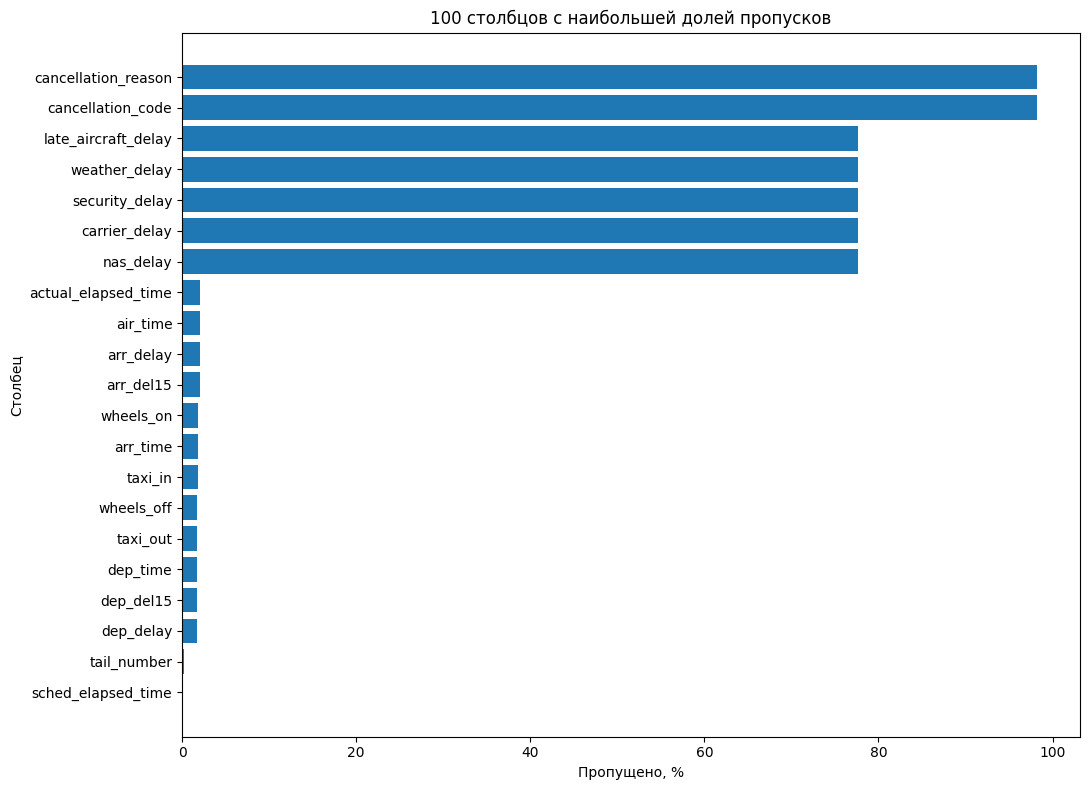

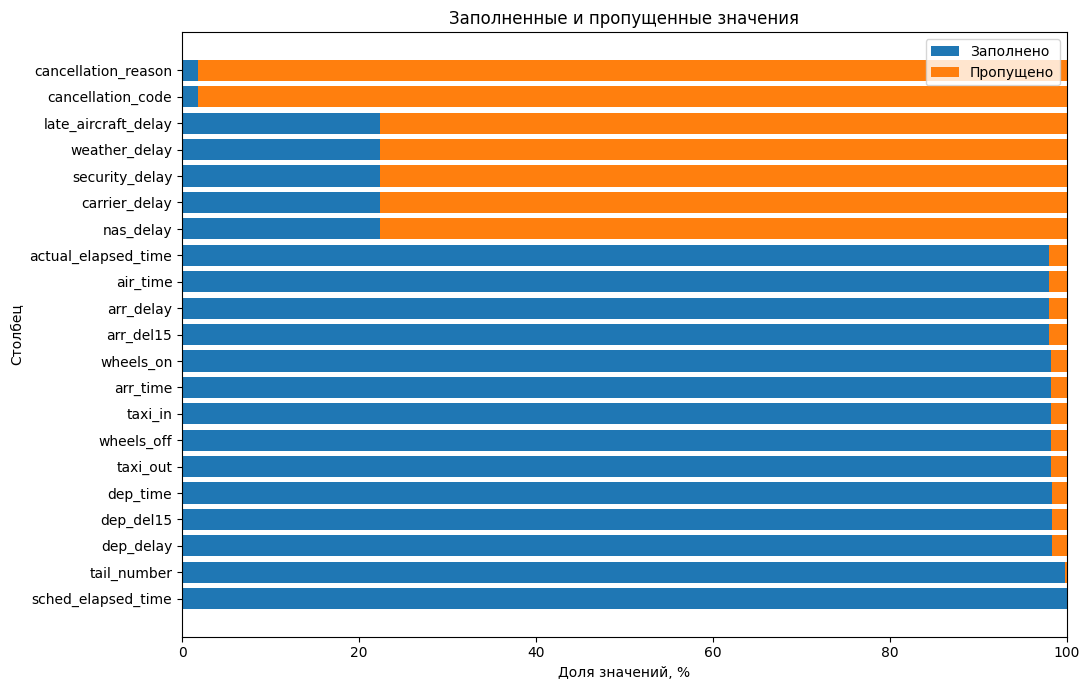

In [11]:
top_missing = missing_flights[missing_flights["Пропущено"] > 0].nlargest(100, "Пропущено, %")

plt.figure(figsize=(11, 8))
plt.barh(top_missing.sort_values("Пропущено, %").index,
        top_missing.sort_values("Пропущено, %")["Пропущено, %"])
plt.xlabel("Пропущено, %")
plt.ylabel("Столбец")
plt.title("100 столбцов с наибольшей долей пропусков")
plt.tight_layout()
plt.show()

small_missing = top_missing.sort_values("Пропущено, %")
filled_percent = 100 - small_missing["Пропущено, %"]

plt.figure(figsize=(11, 7))
plt.barh(small_missing.index, filled_percent, label="Заполнено")
plt.barh(small_missing.index, small_missing["Пропущено, %"],
        left=filled_percent, label="Пропущено")
plt.xlabel("Доля значений, %")
plt.ylabel("Столбец")
plt.title("Заполненные и пропущенные значения")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()


## 3. Проверка целевых столбцов

In [12]:
for column in ["dep_del15", "arr_del15", "cancelled", "diverted"]:
    print()
    print("Столбец:", column)
    display(df_flights[column].value_counts(dropna=False).to_frame("Количество"))

# Проверяем, бывают ли рейсы одновременно отменёнными и перенаправленными
status_table = pd.crosstab(
    df_flights["cancelled"].fillna(-1),
    df_flights["diverted"].fillna(-1)
)
print("Отмена и перенаправление:")
display(status_table)



Столбец: dep_del15


,Количество
dep_del15,
0,8917657
1,2614136
<NA>,198558



Столбец: arr_del15


,Количество
arr_del15,
0,8867893
1,2620457
<NA>,242001



Столбец: cancelled


,Количество
cancelled,
0,11523550
1,206801



Столбец: diverted


,Количество
diverted,
0,11695152
1,35199


Отмена и перенаправление:


diverted,0,1
cancelled,,
0,11488351,35199
1,206801,0


Распределение целевой переменной:


,Количество,"Доля, %"
target_status,,
ON_TIME,8867893,75.60
DELAYED,2620457,22.34
CANCELLED,206801,1.76
DIVERTED,35199,0.30
UNKNOWN,1,0.00


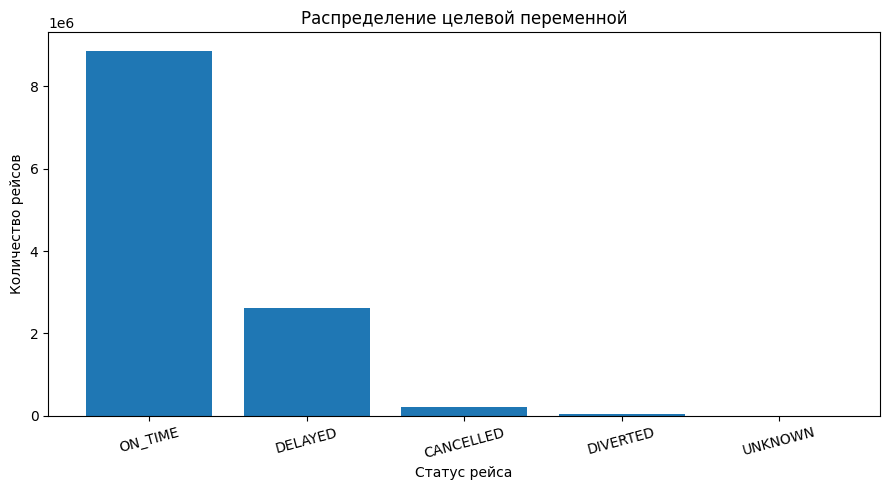

,Количество
target_disrupted,
0,8867893
1,2862457
<NA>,1


In [13]:
was_cancelled = df_flights["cancelled"].eq(1).fillna(False)
was_diverted = df_flights["diverted"].eq(1).fillna(False)
was_delayed = df_flights["arr_del15"].eq(1).fillna(False)
was_on_time = df_flights["arr_del15"].eq(0).fillna(False)

status_values = np.select(
    [
        was_cancelled,
        (~was_cancelled) & was_diverted,
        (~was_cancelled) & (~was_diverted) & was_delayed,
        (~was_cancelled) & (~was_diverted) & was_on_time
    ],
    ["CANCELLED", "DIVERTED", "DELAYED", "ON_TIME"],
    default="UNKNOWN"
)

target_status = pd.Series(status_values, index=df_flights.index, name="target_status").astype("category")

status_counts = target_status.value_counts()
status_table = pd.DataFrame({
    "Количество": status_counts,
    "Доля, %": (status_counts / len(target_status) * 100).round(2)
})
print("Распределение целевой переменной:")
display(status_table)

plt.figure(figsize=(9, 5))
plt.bar(status_counts.index, status_counts.values)
plt.xlabel("Статус рейса")
plt.ylabel("Количество рейсов")
plt.title("Распределение целевой переменной")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

target_disrupted = pd.Series(pd.NA, index=df_flights.index, dtype="Int8")
known_status = target_status != "UNKNOWN"
target_disrupted.loc[known_status] = target_status.loc[known_status].isin(
    ["DELAYED", "CANCELLED", "DIVERTED"]
).astype("int8")

target_disrupted.name = "target_disrupted"
display(target_disrupted.value_counts(dropna=False).to_frame("Количество"))

In [14]:
unknown_count = (target_status == "UNKNOWN").sum()

print("Рейсов с неизвестным статусом:", unknown_count)

known_status = target_status != "UNKNOWN"

df_model = df_flights.loc[known_status].copy()

df_model["target_status"] = target_status.loc[known_status]
df_model["target_disrupted"] = target_disrupted.loc[known_status]

print("Удалено строк:", len(df_flights) - len(df_model))

Рейсов с неизвестным статусом: 1
Удалено строк: 1


In [15]:
df_flights = df_model

,airline_code,flights,delay_share,cancel_share
0,WN,2319717,0.231771,0.009201
1,DL,1721263,0.196422,0.014501
2,AA,1641071,0.258791,0.021477
3,OO,1416733,0.213444,0.015843
4,UA,1354575,0.21578,0.009895
5,YX,592268,0.213174,0.041228
6,MQ,517046,0.202209,0.022687
7,AS,473194,0.216603,0.011769
8,OH,411822,0.276384,0.051918
9,B6,397034,0.27503,0.027595


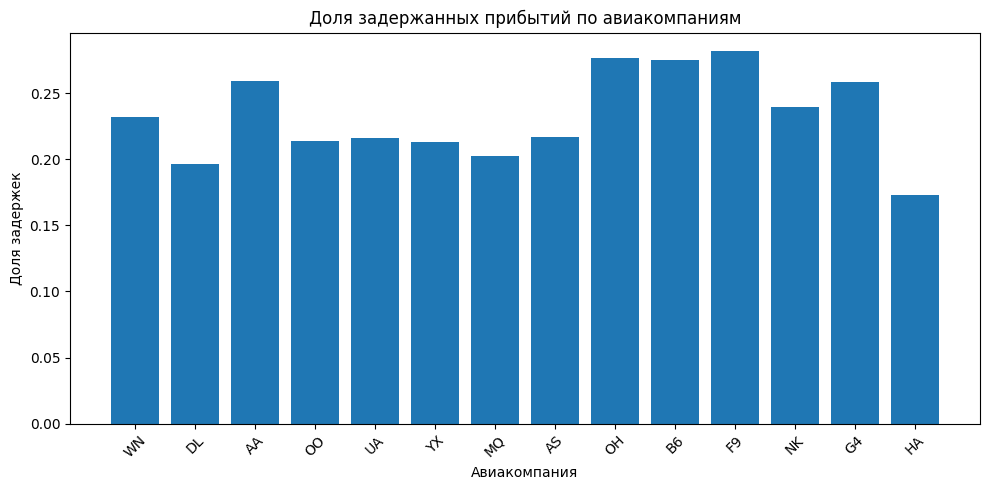

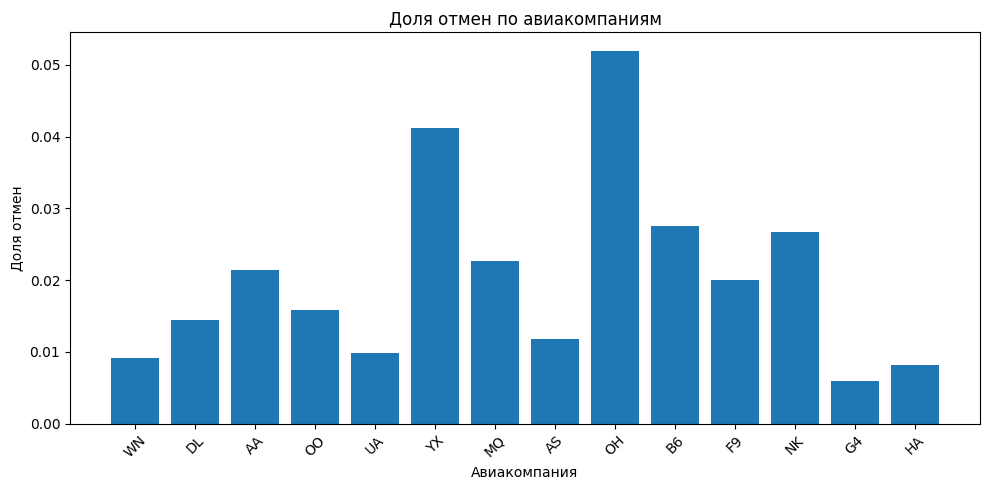

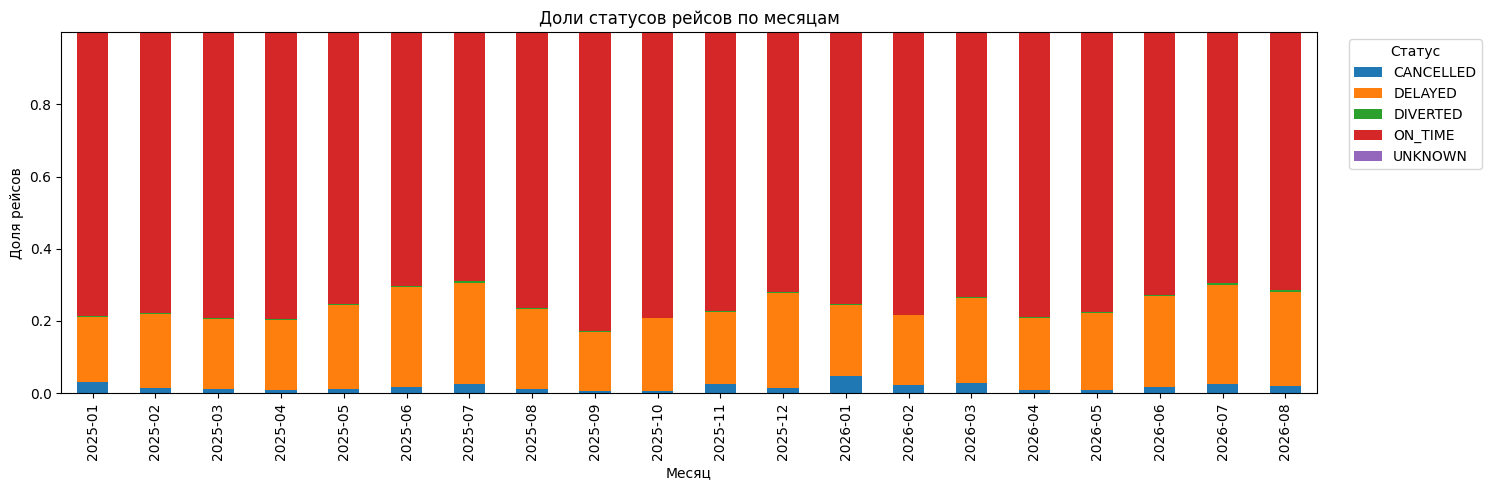

In [16]:
# Сравниваем задержки и отмены у разных авиакомпаний
airline_stats = df_flights.groupby("airline_code", observed=True).agg(
    flights=("airline_code", "size"),
    delay_share=("arr_del15", "mean"),
    cancel_share=("cancelled", "mean")
)

airline_stats = airline_stats.sort_values("flights", ascending=False).head(14).reset_index()
display(airline_stats)

plt.figure(figsize=(10, 5))
plt.bar(airline_stats["airline_code"], airline_stats["delay_share"])
plt.title("Доля задержанных прибытий по авиакомпаниям")
plt.xlabel("Авиакомпания")
plt.ylabel("Доля задержек")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(airline_stats["airline_code"], airline_stats["cancel_share"])
plt.title("Доля отмен по авиакомпаниям")
plt.xlabel("Авиакомпания")
plt.ylabel("Доля отмен")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Смотрим, как менялось распределение статусов по месяцам
monthly_data = pd.DataFrame({
    "month": flight_dates.dt.to_period("M").astype(str),
    "status": target_status.astype(str)
})
monthly_data = monthly_data[monthly_data["month"] != "NaT"]
monthly_share = pd.crosstab(
    monthly_data["month"], monthly_data["status"], normalize="index"
)

monthly_share.plot(kind="bar", stacked=True, figsize=(15, 5))
plt.title("Доли статусов рейсов по месяцам")
plt.xlabel("Месяц")
plt.ylabel("Доля рейсов")
plt.legend(title="Статус", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 4. Анализ причин задержек и отмен

In [17]:
delay_columns = [
    col for col in df_flights.columns
    if "delay" in col.lower()
]
delay_time_columns = ["dep_delay", "arr_delay"]

delay_reasons = [col for col in delay_columns if col not in delay_time_columns]

print()
print("Причины задержек:")
print(delay_reasons)


Причины задержек:
['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']


In [18]:
delayed_flights = df_flights["arr_delay"].ge(15)

rows_with_delay = delayed_flights & df_flights["arr_delay"].notna()
reason_minutes = df_flights.loc[rows_with_delay, delay_reasons].fillna(0)
total_reason_minutes = reason_minutes.sum(axis=1)
difference = total_reason_minutes - df_flights.loc[rows_with_delay, "arr_delay"]

reason_share = (reason_minutes.gt(0).mean() * 100).round(2)
print("Доля задержанных рейсов с каждой причиной, %:")
display(reason_share.to_frame("Доля, %"))

main_reason = reason_minutes.idxmax(axis=1)
no_reason = reason_minutes.max(axis=1).eq(0)
main_reason = main_reason.mask(no_reason, "UNKNOWN_REASON")

print("Самая продолжительная причина задержки:")
display(main_reason.value_counts().to_frame("Количество"))

print("Причины отмены:")
display(df_flights.loc[was_cancelled, "cancellation_reason"].value_counts(dropna=False).to_frame("Количество"))


Доля задержанных рейсов с каждой причиной, %:


,"Доля, %"
carrier_delay,53.31
weather_delay,6.41
nas_delay,50.42
security_delay,0.34
late_aircraft_delay,51.51


Самая продолжительная причина задержки:


,Количество
late_aircraft_delay,1024478
carrier_delay,785254
nas_delay,699515
weather_delay,106043
security_delay,5019
UNKNOWN_REASON,148


Причины отмены:


,Количество
cancellation_reason,
Weather,132935
Carrier,42965
National Air System,30775
Security,126


In [19]:
delayed_flights = df_flights[
    df_flights["arr_del15"] == 1
].copy()

reason_values = delayed_flights[delay_reasons]

has_reason = reason_values.fillna(0).gt(0).any(axis=1)

unknown_flights = delayed_flights.loc[~has_reason].copy()

print("Всего задержанных рейсов:", len(delayed_flights))
print("Рейсов с неизвестной причиной:", len(unknown_flights))

print()
print("Все пять причин пустые:",
      reason_values.loc[~has_reason].isna().all(axis=1).sum())

print("Все пять причин равны 0 или пустые:",
      reason_values.loc[~has_reason].fillna(0).eq(0).all(axis=1).sum())

columns_to_show = [
    "flight_date",
    "airline_code",
    "origin",
    "dest",
    "arr_delay"
] + delay_reasons

display(unknown_flights[columns_to_show].head(20))

Всего задержанных рейсов: 2620457
Рейсов с неизвестной причиной: 148

Все пять причин пустые: 1
Все пять причин равны 0 или пустые: 148


,flight_date,airline_code,origin,dest,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
4818311,2025-09-08,WN,FLL,BWI,75,0,0,0,0,0
5781046,2025-10-28,WN,ABQ,DEN,99,0,0,0,0,0
5829376,2025-10-30,WN,LAS,SAN,198,0,0,0,0,0
6165272,2025-11-17,WN,LAS,BUR,189,0,0,0,0,0
6179642,2025-11-18,WN,SMF,ONT,130,0,0,0,0,0
6184217,2025-11-18,WN,DEN,HOU,98,0,0,0,0,0
6207232,2025-11-20,WN,DEN,AUS,93,0,0,0,0,0
6223763,2025-11-20,WN,LAS,BOI,813,0,0,0,0,0
6223952,2025-11-20,WN,SMF,BOI,820,0,0,0,0,0
6229697,2025-11-21,WN,DEN,BZN,277,0,0,0,0,0


In [20]:
unknown_reason = (
    df_flights["arr_del15"].eq(1)
    & df_flights[delay_reasons].fillna(0).eq(0).all(axis=1)
).fillna(False)

print("Рейсов с неизвестной причиной:", unknown_reason.sum())

df_flights = df_flights.loc[~unknown_reason].copy()

Рейсов с неизвестной причиной: 148


## 5. Числовые данные, выбросы

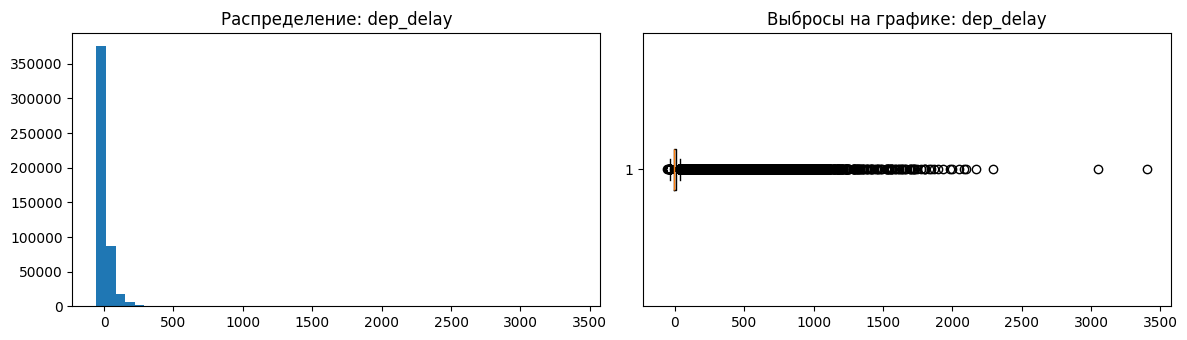

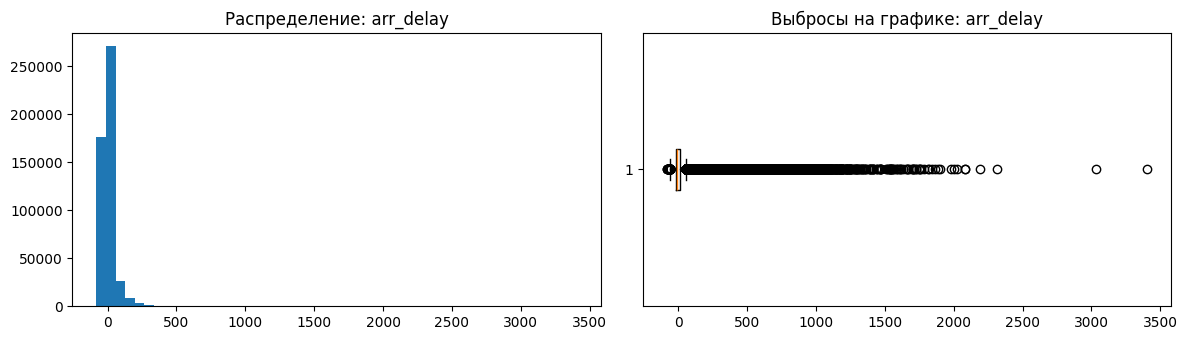

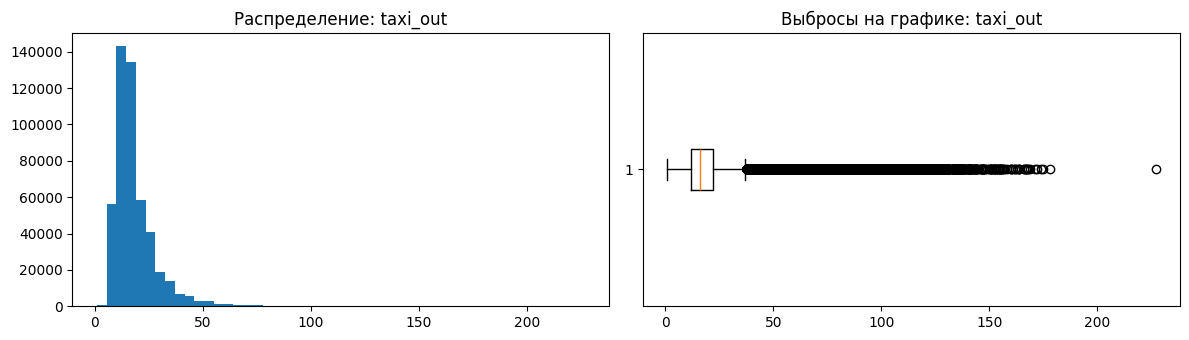

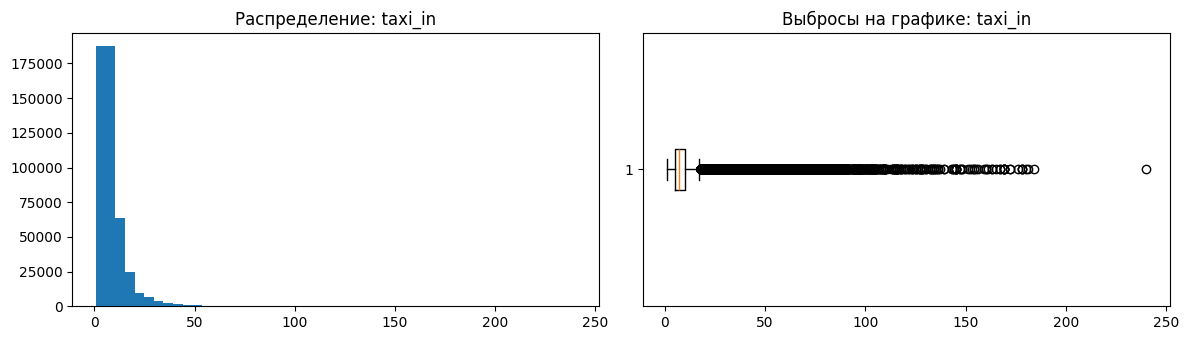

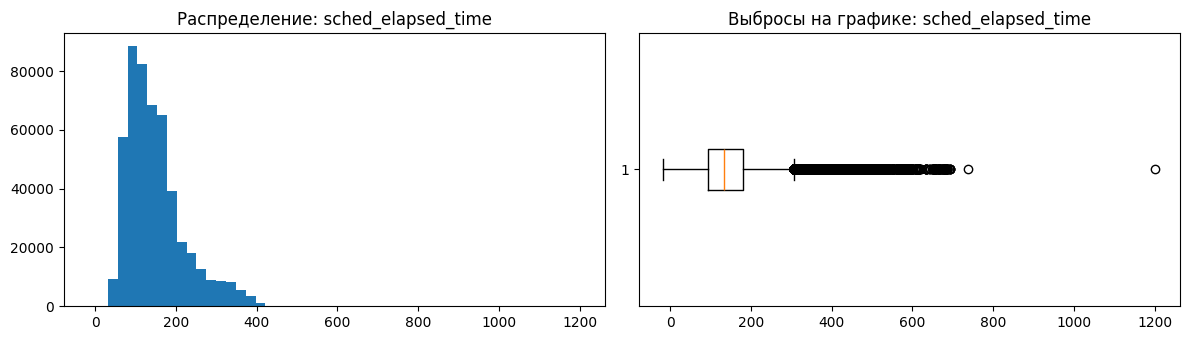

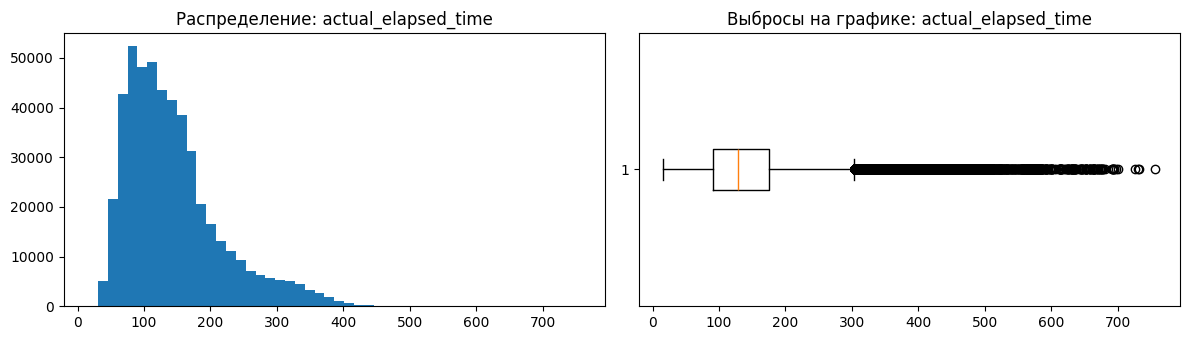

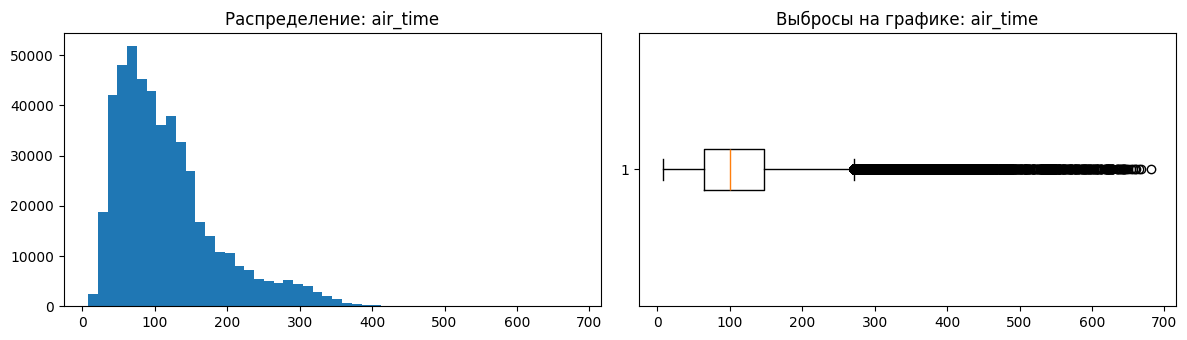

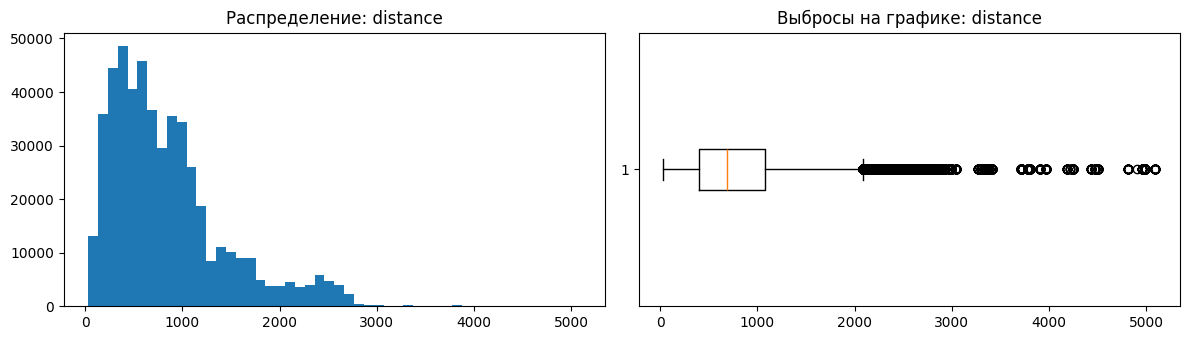

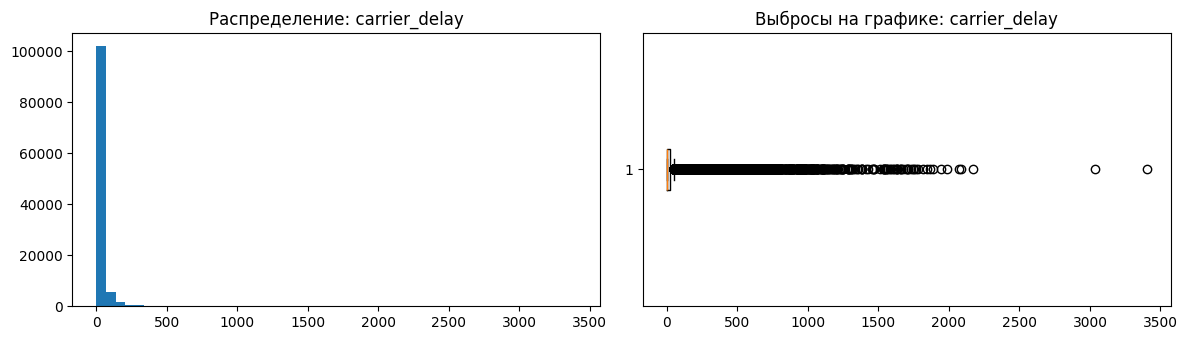

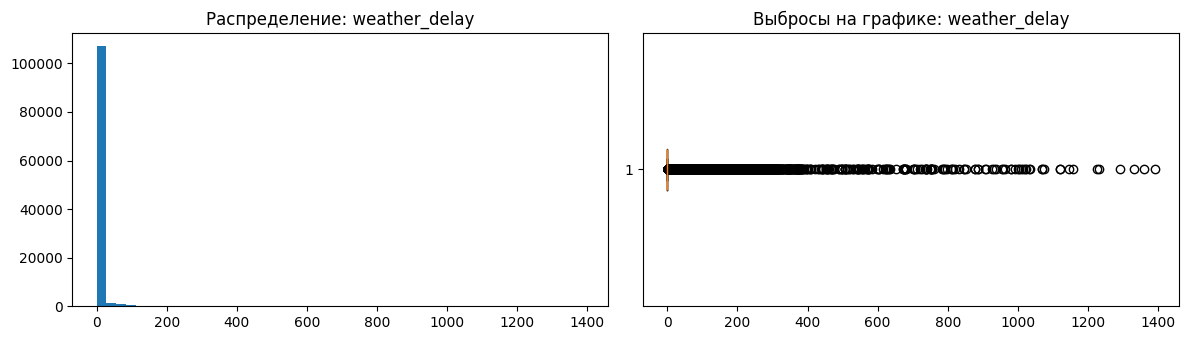

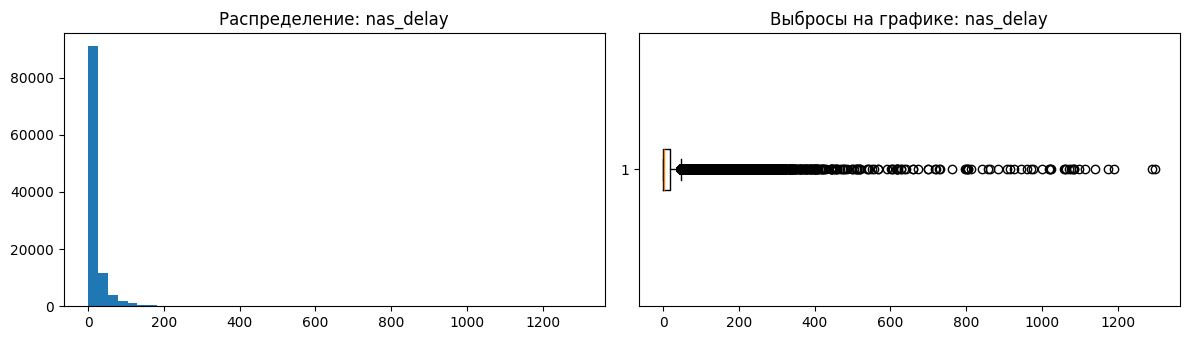

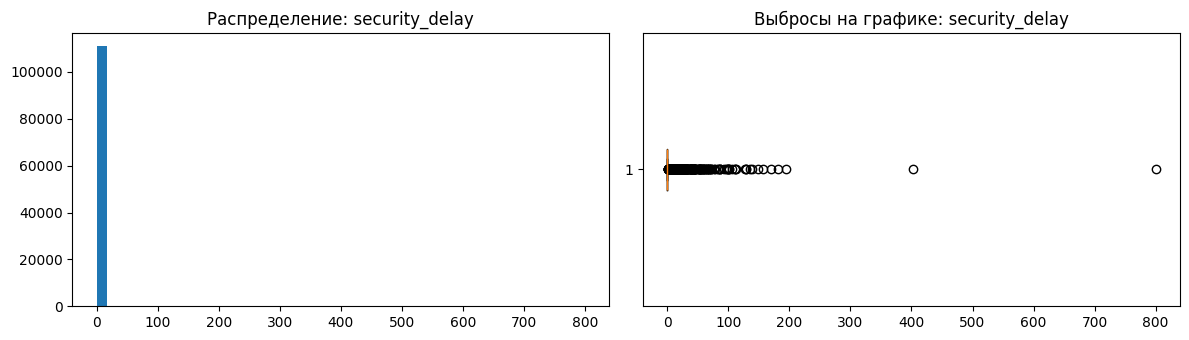

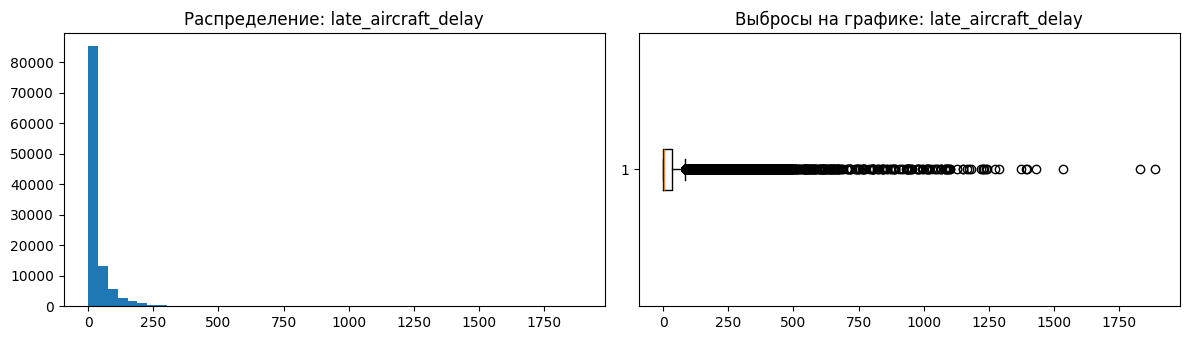

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
dep_delay,11531644.0,14.325108,59.100956,-115.0,-15.0,-11.0,-6.0,-2.0,11.0,92.0,231.0,4380.0
arr_delay,11488202.0,8.831469,61.223563,-128.0,-38.0,-28.0,-16.0,-6.0,12.0,92.0,230.0,4381.0
taxi_out,11524591.0,18.748623,10.81441,1.0,7.0,9.0,12.0,16.0,21.0,38.0,61.0,1274.0
taxi_in,11519381.0,8.74698,7.584309,1.0,2.0,3.0,5.0,7.0,10.0,22.0,39.0,1318.0
sched_elapsed_time,11730198.0,149.837127,73.013769,-99.0,50.0,68.0,95.0,134.0,180.0,309.0,377.0,1510.0
actual_elapsed_time,11488202.0,144.547011,73.407862,14.0,45.0,60.0,91.0,128.0,176.0,302.0,372.0,763.0
air_time,11488202.0,117.069439,71.408395,6.0,24.0,36.0,64.0,100.0,147.0,273.0,337.0,719.0
distance,11730202.0,845.832028,603.087831,31.0,101.0,177.0,404.0,694.0,1080.0,2218.0,2614.0,5095.0
carrier_delay,2620309.0,23.971457,76.064178,0.0,0.0,0.0,0.0,2.0,21.0,102.0,294.0,4380.0
weather_delay,2620309.0,4.687846,35.795612,0.0,0.0,0.0,0.0,0.0,0.0,13.0,123.0,2394.0


In [21]:
number_columns = [
    "dep_delay", "arr_delay", "taxi_out", "taxi_in",
    "sched_elapsed_time", "actual_elapsed_time", "air_time", "distance",
    "carrier_delay", "weather_delay", "nas_delay", "security_delay",
    "late_aircraft_delay"
]
number_columns = [column for column in number_columns if column in df_flights.columns]

plot_data = df_flights[number_columns].sample(
    n=min(500_000, len(df_flights)), random_state=42
)

for column in number_columns:
    values = pd.to_numeric(plot_data[column], errors="coerce").dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    axes[0].hist(values, bins=50)
    axes[0].set_title(f"Распределение: {column}")

    axes[1].boxplot(values, vert=False)
    axes[1].set_title(f"Выбросы на графике: {column}")

    plt.tight_layout()
    plt.show()

# Числовая сводка считается по всем 11,7 млн рейсов
display(df_flights[number_columns].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T)


In [22]:
outlier_rows = []

for column in number_columns:
    values = pd.to_numeric(plot_data[column], errors="coerce").dropna()
    if len(values) == 0:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_count = ((values < lower_limit) | (values > upper_limit)).sum()

    outlier_rows.append({
        "Столбец": column,
        "Нижняя граница": lower_limit,
        "Верхняя граница": upper_limit,
        "Число выбросов": outlier_count,
        "Выбросы, %": round(outlier_count / len(values) * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("Выбросы, %", ascending=False)
display(outlier_report)

for column in ["arr_delay", "dep_delay"]:
    print()
    print("Самые большие значения:", column)
    show_columns = ["flight_date", "airline_code", "origin", "dest", column, "cancelled", "diverted"]
    show_columns = [name for name in show_columns if name in df_flights.columns]
    display(df_flights.nlargest(10, column)[show_columns])


,Столбец,Нижняя граница,Верхняя граница,Число выбросов,"Выбросы, %"
0,dep_delay,-31.5,36.5,64091,13.04
8,carrier_delay,-31.5,52.5,12082,10.85
12,late_aircraft_delay,-51.0,85.0,10873,9.76
1,arr_delay,-58.0,54.0,45069,9.21
10,nas_delay,-28.5,47.5,9358,8.40
3,taxi_in,-2.5,17.5,39764,8.10
9,weather_delay,0.0,0.0,7235,6.50
7,distance,-604.0,2084.0,29435,5.89
2,taxi_out,-3.0,37.0,24759,5.04
6,air_time,-60.5,271.5,24520,5.01



Самые большие значения: arr_delay


,flight_date,airline_code,origin,dest,arr_delay,cancelled,diverted
11598702,2026-08-25,AA,DEN,PHX,4381,0,0
5111718,2025-09-24,AA,MSN,DFW,4336,0,0
5617392,2025-10-20,AA,IAH,ORD,3500,0,0
11525049,2026-08-21,AA,OMA,DFW,3432,0,0
10711660,2026-07-12,AA,BGR,ORD,3425,0,0
951655,2025-02-24,AA,SJU,PHL,3407,0,0
7496333,2026-01-29,AA,SDF,DFW,3339,0,0
476263,2025-01-28,AA,IAH,DFW,3282,0,0
1491413,2025-03-24,AA,RSW,CLT,3275,0,0
2740372,2025-05-27,AA,IAH,MIA,3241,0,0



Самые большие значения: dep_delay


,flight_date,airline_code,origin,dest,dep_delay,cancelled,diverted
11598702,2026-08-25,AA,DEN,PHX,4380,0,0
5111718,2025-09-24,AA,MSN,DFW,4352,0,0
5617392,2025-10-20,AA,IAH,ORD,3475,0,0
11525049,2026-08-21,AA,OMA,DFW,3458,0,0
951655,2025-02-24,AA,SJU,PHL,3403,0,0
10711660,2026-07-12,AA,BGR,ORD,3392,0,0
7496333,2026-01-29,AA,SDF,DFW,3339,0,0
476263,2025-01-28,AA,IAH,DFW,3298,0,0
1491413,2025-03-24,AA,RSW,CLT,3288,0,0
5539009,2025-10-16,AA,BDL,ORD,3239,0,0


## 6. Новая очищенная таблица, ближе к итоговой

In [23]:
def is_bad_time(column):
    time_value = pd.to_numeric(column, errors="coerce")
    bad_value = (
        time_value.notna()
        & time_value.ne(2400)
        & (
            time_value.lt(0)
            | time_value.gt(2359)
            | time_value.mod(100).ge(60)
        )
    )
    return bad_value.fillna(False)

In [24]:
flight_columns = [
    "flight_date", "year", "month", "day_of_week", "airline_code",
    "flight_number", "origin", "dest", "sched_dep_time",
    "sched_arr_time", "sched_elapsed_time", "distance", "dep_time_block"
]
flight_columns = [column for column in flight_columns if column in df_flights.columns]

df_model = df_flights[flight_columns].copy()
df_model["flight_date"] = pd.to_datetime(df_model["flight_date"], errors="coerce")

# целевые переменные
df_model["target_status"] = target_status
df_model["target_disrupted"] = target_disrupted

bad_duration = df_model["sched_elapsed_time"].notna() & (df_model["sched_elapsed_time"] <= 0)
print("Некорректная запланированная длительность:", int(bad_duration.sum()))
df_model.loc[bad_duration, "sched_elapsed_time"] = np.nan

def time_to_minutes(column):
    time_value = pd.to_numeric(column, errors="coerce")
    minutes = (time_value // 100) * 60 + (time_value % 100)
    minutes = minutes.mask(time_value.eq(2400), 0)
    minutes = minutes.mask(is_bad_time(column))
    return minutes

if "sched_dep_time" in df_model.columns:
    df_model["sched_dep_minutes"] = time_to_minutes(df_model["sched_dep_time"]) #в sched_dep_time это у нас время 5:59 -> 559
    df_model["sched_dep_hour"] = df_model["sched_dep_minutes"] // 60

if "sched_arr_time" in df_model.columns:
    df_model["sched_arr_minutes"] = time_to_minutes(df_model["sched_arr_time"])

# собираем дату и запланированное время вылета в одну временную метку
# исплючение 2400
if "sched_dep_time" in df_model.columns:
    next_day = pd.to_numeric(df_model["sched_dep_time"], errors="coerce").eq(2400)
    df_model["sched_dep_datetime"] = (
        df_model["flight_date"]
        + pd.to_timedelta(df_model["sched_dep_minutes"], unit="m")
        + pd.to_timedelta(next_day.astype("int8"), unit="D")
    )

print("Размер рабочей таблицы:", df_model.shape)
display(df_model.head())


Некорректная запланированная длительность: 14
Размер рабочей таблицы: (11730202, 19)


,flight_date,year,month,day_of_week,airline_code,flight_number,origin,dest,sched_dep_time,sched_arr_time,sched_elapsed_time,distance,dep_time_block,target_status,target_disrupted,sched_dep_minutes,sched_dep_hour,sched_arr_minutes,sched_dep_datetime
0,2025-01-01,2025,1,3,DL,2080,SFO,MSP,10,559,229,1589,0001-0559,ON_TIME,0,10,0,359,2025-01-01 00:10:00
1,2025-01-01,2025,1,3,AA,2509,SFO,CLT,17,818,301,2296,0001-0559,ON_TIME,0,17,0,498,2025-01-01 00:17:00
2,2025-01-01,2025,1,3,AA,2158,SMF,ORD,25,634,249,1781,0001-0559,ON_TIME,0,25,0,394,2025-01-01 00:25:00
3,2025-01-01,2025,1,3,AS,210,FAI,SEA,25,503,218,1533,0001-0559,ON_TIME,0,25,0,303,2025-01-01 00:25:00
4,2025-01-01,2025,1,3,AA,1677,LAX,ORD,27,637,250,1744,0001-0559,ON_TIME,0,27,0,397,2025-01-01 00:27:00


## 7. Добавление информации об авиакомпаниях и аэропортах

In [25]:
airline_names = (
    df_airlines.drop_duplicates("airline_code")
    .set_index("airline_code")["airline"]
)
airport_info = (
    df_airports.drop_duplicates("iata_code")
    .set_index("iata_code")
)

df_model_joined = df_model

df_model_joined["airline_name"] = df_model_joined["airline_code"].map(airline_names)

for column in ["latitude", "longitude", "elevation_ft", "airport_type"]:
    df_model_joined["origin_" + column] = df_model_joined["origin"].map(airport_info[column])
    df_model_joined["dest_" + column] = df_model_joined["dest"].map(airport_info[column])

print("Не найдено названий авиакомпаний:", df_model_joined["airline_name"].isna().sum())
print("Не найдены координаты аэропорта вылета:", df_model_joined["origin_latitude"].isna().sum())
print("Не найдены координаты аэропорта прибытия:", df_model_joined["dest_latitude"].isna().sum())

display(df_model_joined[[
    "airline_code", "airline_name", "origin", "origin_latitude",
    "dest", "dest_latitude"
]].head())

Не найдено названий авиакомпаний: 0
Не найдены координаты аэропорта вылета: 0
Не найдены координаты аэропорта прибытия: 0


,airline_code,airline_name,origin,origin_latitude,dest,dest_latitude
0,DL,Delta Air Lines,SFO,37.619806,MSP,44.880081
1,AA,American Airlines,SFO,37.619806,CLT,35.214001
2,AA,American Airlines,SMF,38.695400,ORD,41.978600
3,AS,Alaska Airlines,FAI,64.815102,SEA,47.447943
4,AA,American Airlines,LAX,33.942501,ORD,41.978600


In [26]:
df_model_joined.head()

,flight_date,year,month,day_of_week,airline_code,flight_number,origin,dest,sched_dep_time,sched_arr_time,...,sched_dep_datetime,airline_name,origin_latitude,dest_latitude,origin_longitude,dest_longitude,origin_elevation_ft,dest_elevation_ft,origin_airport_type,dest_airport_type
0,2025-01-01,2025,1,3,DL,2080,SFO,MSP,10,559,...,2025-01-01 00:10:00,Delta Air Lines,37.619806,44.880081,-122.374821,-93.221741,13,841,large_airport,large_airport
1,2025-01-01,2025,1,3,AA,2509,SFO,CLT,17,818,...,2025-01-01 00:17:00,American Airlines,37.619806,35.214001,-122.374821,-80.943100,13,748,large_airport,large_airport
2,2025-01-01,2025,1,3,AA,2158,SMF,ORD,25,634,...,2025-01-01 00:25:00,American Airlines,38.695400,41.978600,-121.591003,-87.904800,27,680,large_airport,large_airport
3,2025-01-01,2025,1,3,AS,210,FAI,SEA,25,503,...,2025-01-01 00:25:00,Alaska Airlines,64.815102,47.447943,-147.856003,-122.310276,439,433,medium_airport,large_airport
4,2025-01-01,2025,1,3,AA,1677,LAX,ORD,27,637,...,2025-01-01 00:27:00,American Airlines,33.942501,41.978600,-118.407997,-87.904800,125,680,large_airport,large_airport


In [27]:
display(df_model_joined.info())
display(df_model_joined.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 11730202 entries, 0 to 11730350
Data columns (total 28 columns):
 #   Column               Dtype         
---  ------               -----         
 0   flight_date          datetime64[ns]
 1   year                 int16         
 2   month                int8          
 3   day_of_week          int8          
 4   airline_code         category      
 5   flight_number        Int32         
 6   origin               category      
 7   dest                 category      
 8   sched_dep_time       Int16         
 9   sched_arr_time       Int16         
 10  sched_elapsed_time   Int16         
 11  distance             Int16         
 12  dep_time_block       category      
 13  target_status        category      
 14  target_disrupted     Int8          
 15  sched_dep_minutes    Int16         
 16  sched_dep_hour       Int16         
 17  sched_arr_minutes    Int16         
 18  sched_dep_datetime   datetime64[ns]
 19  airline_name         cat

None

,flight_date,year,month,day_of_week,flight_number,sched_dep_time,sched_arr_time,sched_elapsed_time,distance,target_disrupted,sched_dep_minutes,sched_dep_hour,sched_arr_minutes,sched_dep_datetime,origin_latitude,dest_latitude,origin_longitude,dest_longitude,origin_elevation_ft,dest_elevation_ft
count,11730202,1.173020e+07,1.173020e+07,1.173020e+07,11730202.0,11730202.0,11730202.0,11730184.0,11730202.0,11730202.0,11730202.0,11730202.0,11730202.0,11730202,1.173020e+07,1.173020e+07,1.173020e+07,1.173020e+07,1.173020e+07,1.173020e+07
mean,2025-11-03 09:18:19.737789696,2.025403e+03,5.780369e+00,4.004797e+00,2539.079923,1324.300663,1494.365653,149.837371,845.832028,0.244012,805.369831,12.973266,908.571887,2025-11-03 22:43:41.935025408,3.664996e+01,3.665006e+01,-9.513926e+01,-9.513902e+01,9.132541e+02,9.131999e+02
min,2025-01-01 00:00:00,2.025000e+03,1.000000e+00,1.000000e+00,1.0,1.0,1.0,5.0,31.0,0.0,0.0,0.0,0.0,2025-01-01 00:10:00,-1.433100e+01,-1.433100e+01,-1.766428e+02,-1.766428e+02,3.000000e+00,3.000000e+00
25%,2025-06-05 00:00:00,2.025000e+03,3.000000e+00,2.000000e+00,1218.0,904.0,1104.0,95.0,404.0,0.0,544.0,9.0,664.0,2025-06-05 19:59:00,3.289680e+01,3.289680e+01,-1.116698e+02,-1.116698e+02,3.600000e+01,3.600000e+01
50%,2025-11-01 00:00:00,2.025000e+03,6.000000e+00,4.000000e+00,2291.0,1317.0,1519.0,134.0,694.0,0.0,797.0,13.0,919.0,2025-11-01 23:56:30,3.736245e+01,3.736245e+01,-8.906984e+01,-8.906984e+01,5.990000e+02,5.990000e+02
75%,2026-04-07 00:00:00,2.026000e+03,8.000000e+00,6.000000e+00,3680.0,1735.0,1929.0,180.0,1080.0,0.0,1055.0,17.0,1168.0,2026-04-07 08:45:00,4.077720e+01,4.077720e+01,-8.119998e+01,-8.119998e+01,9.250000e+02,9.250000e+02
max,2026-08-31 00:00:00,2.026000e+03,1.200000e+01,7.000000e+00,9914.0,2400.0,2400.0,1510.0,5095.0,1.0,1439.0,23.0,1439.0,2026-08-31 23:59:00,7.128540e+01,7.128540e+01,1.457288e+02,1.457288e+02,7.820000e+03,7.820000e+03
std,NaN,4.905231e-01,3.141914e+00,2.010679e+00,1629.977248,492.464578,518.679693,73.013463,603.087831,0.4295,297.036119,4.891167,311.668877,NaN,6.034591e+00,6.034643e+00,1.845148e+01,1.845168e+01,1.421698e+03,1.421635e+03


In [31]:
df_model_joined = df_model_joined.drop('airline_name', axis=1).copy()
df_model_joined.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11730202 entries, 0 to 11730350
Data columns (total 27 columns):
 #   Column               Dtype         
---  ------               -----         
 0   flight_date          datetime64[ns]
 1   year                 int16         
 2   month                int8          
 3   day_of_week          int8          
 4   airline_code         category      
 5   flight_number        Int32         
 6   origin               category      
 7   dest                 category      
 8   sched_dep_time       Int16         
 9   sched_arr_time       Int16         
 10  sched_elapsed_time   Int16         
 11  distance             Int16         
 12  dep_time_block       category      
 13  target_status        category      
 14  target_disrupted     Int8          
 15  sched_dep_minutes    Int16         
 16  sched_dep_hour       Int16         
 17  sched_arr_minutes    Int16         
 18  sched_dep_datetime   datetime64[ns]
 19  origin_latitude      flo

In [33]:
df_model_joined.to_csv("df_model.csv", index=False)

## Доп стата

In [29]:
columns_after_departure = [
    "dep_time", "dep_delay", "dep_del15", "taxi_out", "wheels_off",
    "wheels_on", "taxi_in", "arr_time", "arr_delay", "arr_del15",
    "cancelled", "cancellation_code", "cancellation_reason", "diverted",
    "actual_elapsed_time", "air_time", "carrier_delay", "weather_delay",
    "nas_delay", "security_delay", "late_aircraft_delay"
] # - эти столбцы нельзя в модель до вылета, т.к. они известы только после прилета